# Two nodes - Atom loading analysis
Valid for master-satellite two-node runs (GeneralVariableScan_master_satellite_two_nodes, Two_nodes_atom_loading_experiment) from 2026-10-07 until ...

Ported from standalone/Two photon analysis/two_nodes_atom_loading.ipynb, which analysed the two standalone systems synchronised by TTL. The loading structure is the same: both traps load at once, all four SPCMs read both out together, and the cut is the joint two_atom_threshold. What is different now:
* All four SPCMs are master-local and each sees BOTH traps through the beamsplitter, so SPCM0, SPCM1, SPCM0_OtherNode and SPCM1_OtherNode are detectors H1, V1, H2 and V2, not "this node" and "the other node". Loading and retention are joint: the readout cannot tell which trap lost its atom.
* Per-node settings and monitors carry _Node1/_Node2 (t_FORT_drop_Node1, FORT_MM_monitor_Node2); joint ones are bare (two_atom_threshold, n_measurements). Loaded with ms_two_nodes_archive_and_datasets_to_locals.
* "loading rate" is, as before, the fraction of first shots above the cut. It includes measurements that reused the atoms left by the previous second shot, so it is higher than the chance that a fresh load gives two atoms (RID 39108: 0.64 overall, 0.57 over fresh loads).
* In confirm-by-first-shot runs (advance_if_atom_in_first_shot, or the retired Two_nodes_atom_loading_2_experiment) the first shot is bright by construction, so loading is plotted as 1/mean(n_first_shot_confirm_tries).
* A 0 in Atom_loading_time is a load the loader gave up on, not an instant load.
* Two-node runs record no magnetometer data, so the magnetometer cell is gone.

In [3]:
date_filters = ["2026-10-21"]

### which two-node sequences to list. The file name alone also matches the
### alternating-shot and alternating-retention runs.
experiment_functions = ["Two_nodes_atom_loading_experiment",
                        "Two_nodes_atom_loading_2_experiment"]


from matplotlib import pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import csv
import numpy as np
import os,sys
import PIL # for reading tif images
import h5py
import datetime as dt
import time
from scipy.optimize import curve_fit
from skimage.filters import threshold_otsu
from IPython.display import display, HTML ## for large prints
import math
import itertools

sys.path.append("..\\")
from h5_data_utilities import * # helper functions for dealing with h5 files

def average_over_measurement(measurements, history):
    iteration = len(history) // measurements
    mean_by_iteration = [np.mean(history[j * measurements:(j + 1) * measurements]) for j in range(iteration)]
    return mean_by_iteration


### one file per RID: the plain file ARTIQ writes when a run ends, or the copy
### the GVS rewrites after every scan point while a run is still going
fnames = ms_two_nodes_files(date_filters, # only find files from these date directories
                            experiment_functions=experiment_functions,
                            start_dir=results,
)


only_show_i_greater_than = -1

print(f"found {len(fnames)} files")
for i,f in enumerate(fnames):
    if i > only_show_i_greater_than:
        try:
            with h5py.File(f, "r") as h:
                rid = h['rid'][()]
                scan_str = ms_scan_label(h)
                function = ms_get(h, 'experiment_function')
                n_meas = ms_get(h, 'n_measurements')
                n_points = len(h['datasets']['scan_sequence1']) * len(h['datasets']['scan_sequence2'])
                n_done = (len(h['datasets']['AllSPCMs_RO1']) - 1) // n_meas
            status = "" if n_done == n_points else f", {n_done} of {n_points} points"
            if "_TwoNodes_" in os.path.basename(f):
                status += ", copy written while the run was going"
            print(f"file {i} (RID {rid}, {function}) scanned over "+scan_str+status)
        except Exception as error:
            print(f"file {i}: oops... something wrong with {f}")
            print(f"    {type(error).__name__}: {error}")

found 0 files


## Combine files and fit

experiment: Two_nodes_atom_loading_experiment
override Node1: {'t_FORT_drop':10*us}
override Node2: {'t_FORT_drop':10*us}
10000 measurements, 6627 loads, 456 loader give-ups, 1.51 measurements per load
# of iterations:  100 
threshold: 42000 counts/s


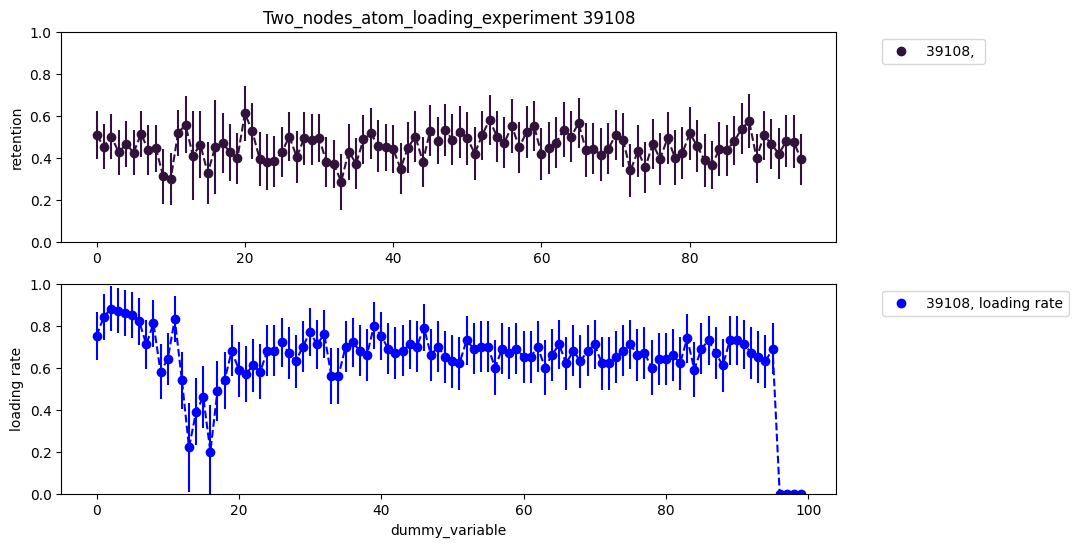

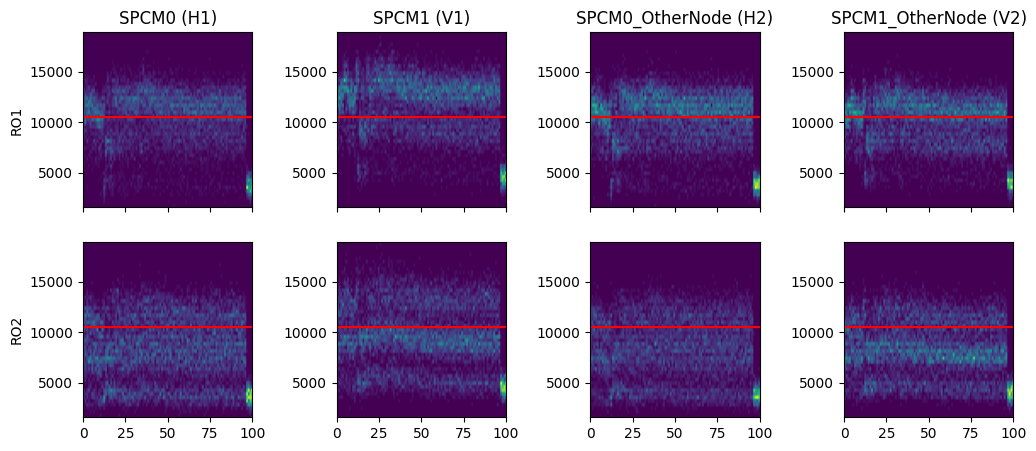

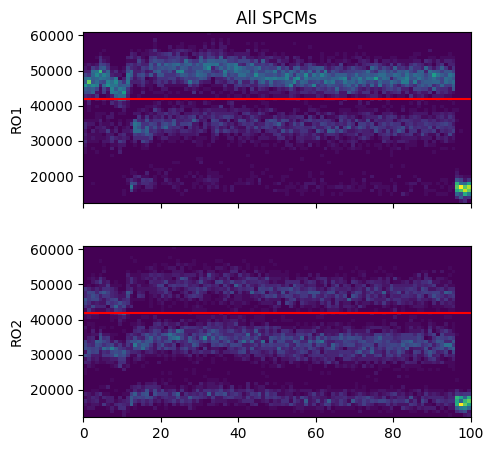

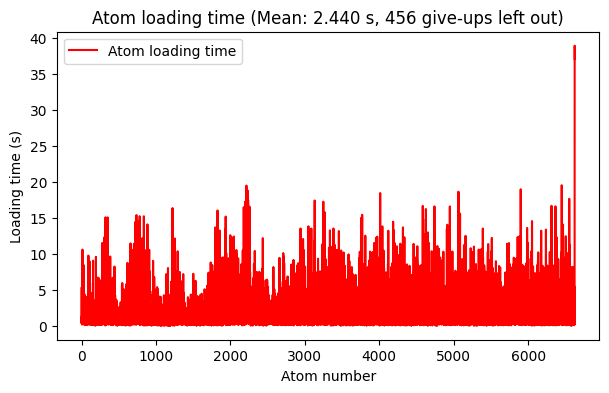

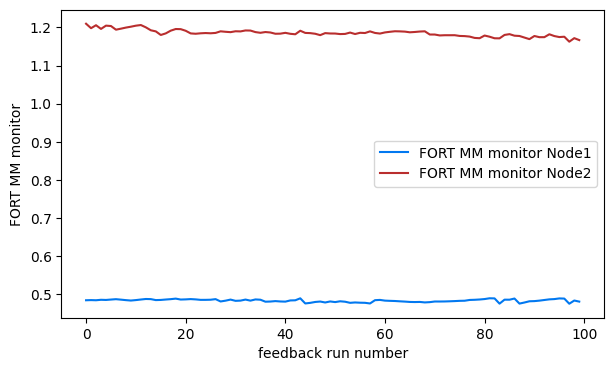

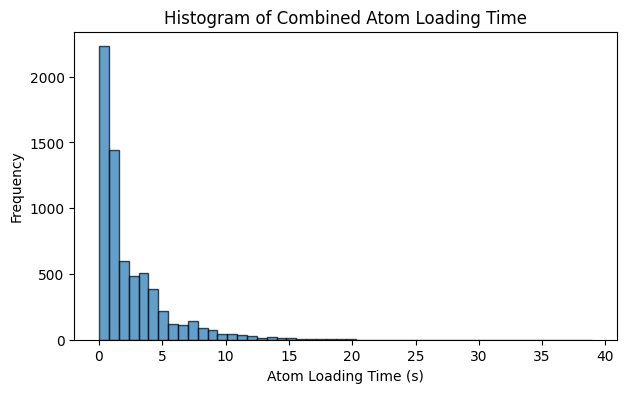

In [2]:
### the file(s) to analyze:
file_indices = {
    0:''
}

# file_indices = {i: '' for i in range(0, 17, 2)}

compare = True # compare multiple files in the same retention and loading plots

otsu_threshold = False # compute threshold using Otsu method instead doing it by eye. only work when require atom loading = False

### manual_threshold = False uses each run's own two_atom_threshold, the joint
### rate the sequence compared the first shot against. The standalone setting
### was True with 36000. On RID 39108 that is on the upper flank of the
### one-atom peak (~34k), below the one/two-atom valley (~39k), so one-atom
### shots would count as loaded.
user_set_manual_threshold = 36000
manual_threshold = False


showhist = True
showloading = True
custom_xlabel = True
merge_data = False # if True, the datasets will be combined, and if fit=True, the new merged data will be fit. don't try this in 2D
fit = True

showhist_counts = False

# for plotting
legend_vars =[]   # e.g. ['t_FORT_drop_Node1', 't_FORT_drop_Node2']: per-node names keep their suffix
xform_and_label = {}
loc='best'
ret_cmap = mpl.colormaps['turbo']
ldng_cmap = mpl.colormaps['winter']

if compare:
    if showloading:
        fig_ret,axes = plt.subplots(nrows=2, sharex=False, figsize=(10, 6))
        ax_ret, ax_ldng = axes
    else:
        fig_ret,ax_ret = plt.subplots()


def point_grid(per_point, iterations, shape):
    """One value per scan point -> the (variable2, variable1) grid; NaN where
    the run did not get to the point."""
    grid = np.full(shape[0] * shape[1], np.nan)
    grid[:iterations] = per_point[:iterations]
    return np.reshape(grid, shape, order='F') # rows have constant variable2


def make_fit_dict(x, retention):
    """The retention-dip fit, started from the lowest retention in the data."""
    ### Auto-detect rough center from minimum retention
    initial_center = x[np.argmin(retention)] if len(x) else 0.0
    p0 = [initial_center, 10e3, 0.9] # [center, width, depth]

    ### using a  Gaussian function for now. Not for a dummy_variable scan,
    ### where a dip means nothing.
    if scan_variable1_name == 'dummy_variable' or len(x) <= 3:
        return {}
    return {
        scan_variable1_name: {
            'model': lambda x, center, sigma, depth: 0.80*(1 - depth * np.exp(-((x - center)**2/(2*sigma**2)))),
            'p0': p0,
            'bounds': ([min(x), 0, 0], [max(x), np.inf, 1]),
            'params': ['center', 'sigma', 'depth']
        }
    }


SPCM0_RO1_hists = []
SPCM0_RO2_hists = []
SPCM1_RO1_hists = []
SPCM1_RO2_hists = []
SPCM0_OtherNode_RO1_hists = []
SPCM0_OtherNode_RO2_hists = []
SPCM1_OtherNode_RO1_hists = []
SPCM1_OtherNode_RO2_hists = []
AllSPCMs_RO1_hists = []
AllSPCMs_RO2_hists = []

merged_retention = np.array([])
merged_scan_sequence1 = np.array([])
merged_errs = np.array([])
rid_str = ''

all_atom_loading_times = []
all_atom_loading_wall_clocks = []
all_FORT_MM_monitor = {node: [] for node in MASTER_SATELLITE_NODES}

analysed = []   # (experiment_function, rid) of each file with a whole scan point
loading_ylabels = set()

for idx,f_item in enumerate(file_indices.items()):
    f_idx,f_comment = f_item   # idx - f_item = {f_idx: f_comment}
    ### read-only, and closed as soon as it is loaded: a run that is still
    ### going rewrites its file after every scan point
    with h5py.File(fnames[f_idx], "r") as f:
        rid = f['rid'][()]
        ms_two_nodes_archive_and_datasets_to_locals(f, parent_locals=locals(), quiet=True)
        print("experiment:",experiment_function)
        ms_print_overrides(f)

        ### Straight from this file, because older runs lack them and a name
        ### loaded from an earlier file would otherwise linger in locals().
        ### n_first_shot_confirm_tries gets one entry per measurement only in
        ### confirm-by-first-shot runs.
        datasets = f['datasets']
        confirm_tries = (datasets['n_first_shot_confirm_tries'][1:]
                         if 'n_first_shot_confirm_tries' in datasets else np.array([]))
        ### the try cap; renamed from max_loading_rounds_two_node on 2026-10-13
        max_tries = next((group[name][()] for group in (datasets, f['archive'])
                          for name in ('max_loading_rounds', 'max_loading_rounds_two_node')
                          if name in group), None)
        for node in MASTER_SATELLITE_NODES:
            if f'FORT_MM_monitor_{node}' in datasets:
                all_FORT_MM_monitor[node].append(datasets[f'FORT_MM_monitor_{node}'][:])

    ### One Atom_loading_time entry per load attempt. A 0 is an attempt the
    ### loader gave up on after max_loading_rounds; a measurement that reused
    ### the atoms from the previous second shot adds no entry.
    all_atom_loading_times.append(Atom_loading_time[1:])
    all_atom_loading_wall_clocks.append(atom_loading_wall_clock[1:])
    n_loads = int(np.count_nonzero(Atom_loading_time[1:]))
    print(f"{len(AllSPCMs_RO1)} measurements, {n_loads} loads, "
          f"{len(Atom_loading_time) - 1 - n_loads} loader give-ups"
          + (f", {len(AllSPCMs_RO1) / n_loads:.2f} measurements per load" if n_loads else ""))

    n_points = len(scan_sequence1) * len(scan_sequence2)
    ### whole scan points only: an aborted run ends in a partial point, and
    ### get_loading_and_retention divides by n_measurements
    n_whole = min(n_points, len(AllSPCMs_RO1) // n_measurements)
    if n_whole == 0:
        print(f"RID {rid}: no whole scan point ({len(AllSPCMs_RO1)} of {n_measurements} measurements), "
              "so no retention, loading or histograms; its loading times and FORT MM monitor are still plotted below")
        continue
    iterations = n_whole
    print("# of iterations: ", iterations, "" if iterations == n_points else f"of {n_points}, the run did not finish")
    analysed.append((experiment_function, rid))

    if otsu_threshold:
        # thresh = threshold_otsu(BothSPCMs_RO1)
        thresh = threshold_otsu(AllSPCMs_RO1)
        cutoff1 = cutoff2 = thresh

        print(f"threshold_otsu: {thresh / t_SPCM_first_shot:.0f} counts/s; get_loading_and_retention "
              "re-cuts every point whose loading is above 0.3 at that point's own Otsu threshold")
    elif manual_threshold:
        cutoff1 = user_set_manual_threshold * t_SPCM_first_shot
        cutoff2 = user_set_manual_threshold * t_SPCM_second_shot
    else:
        ### the sequence's own criterion: the summed counts/s of all four SPCMs
        ### against the joint two_atom_threshold
        cutoff1 = two_atom_threshold * t_SPCM_first_shot
        cutoff2 = two_atom_threshold * t_SPCM_second_shot
    if not otsu_threshold:
        print(f"threshold: {cutoff1 / t_SPCM_first_shot:.0f} counts/s")
    ### in counts/s, for the histogram lines
    hist_cut1, hist_cut2 = cutoff1 / t_SPCM_first_shot, cutoff2 / t_SPCM_second_shot


    ### for plotting
    ### xsteps_xform is a function that can transform scan_sequence1 for plotting. Here it is equal to identity, i.e. no change in scan_sequence1.
    if scan_variable1_name in xform_and_label and custom_xlabel:
        xsteps_xform, xlabel = (xform_and_label[scan_variable1_name]['xsteps_xform'], xform_and_label[scan_variable1_name]['xlabel'])
    else:
        xsteps_xform, xlabel = (lambda x: x, scan_variable1_name)


    legend_string = ''
    for a in legend_vars:
        legend_string += f'{a}={locals()[a]}, '
    legend_string = legend_string[:-2]
    f_comment += legend_string


    ### get_loading_and_retention
    ### These array have length = iterations
    retention_array, loading_rate_array, n_atoms_loaded_array = get_loading_and_retention(AllSPCMs_RO1, AllSPCMs_RO2, n_measurements, iterations, cutoff1, cutoff2=cutoff2, otsu=otsu_threshold)

    ### Confirm-by-first-shot runs retry load + first shot until the first shot
    ### is bright, so the RO1 fraction above is ~1 by construction. Their
    ### loading probability is 1/mean(tries) per scan point. A try count equal
    ### to max_loading_rounds may be a give-up rather than a success; the
    ### dark first shot tells them apart.
    confirm_mode = len(confirm_tries) > 0
    if confirm_mode:
        print("confirm-by-first-shot run: loading is plotted as 1/mean(n_first_shot_confirm_tries)")
        n_shared = min(len(confirm_tries), len(AllSPCMs_RO1))
        if max_tries is not None:
            n_confirm_give_ups = int(np.sum((confirm_tries[:n_shared] == max_tries)
                                            & (AllSPCMs_RO1[:n_shared] <= cutoff1)))
            print(f"{n_confirm_give_ups} measurements used all {max_tries} tries without a bright "
                  "first shot; each counts as a success on the last try in 1/mean(tries)")
        p_load_array = np.full(iterations, np.nan)
        p_load_err_array = np.full(iterations, np.nan)
        for i in range(iterations):
            tries = confirm_tries[i*n_measurements:(i+1)*n_measurements]
            if len(tries) > 0:
                p_load_array[i] = 1 / tries.mean()
                p_load_err_array[i] = tries.std() / np.sqrt(len(tries)) / tries.mean()**2


    ### Necessary to analyze data with 2 scan_sequences
    ### reshaping each array into a 2D array with shape = shape, with order = 'F' (Fortran-style) to sort column by column

    ncols = len(scan_sequence2)
    nrows = len(scan_sequence1)
    shape = (len(scan_sequence2),len(scan_sequence1))
    loading_rate_raveled = point_grid(loading_rate_array, iterations, shape)
    n_atoms_loaded_raveled = point_grid(n_atoms_loaded_array, iterations, shape)
    retention_raveled = point_grid(retention_array, iterations, shape)
    if confirm_mode:
        p_load_raveled = point_grid(p_load_array, iterations, shape)
        p_load_err_raveled = point_grid(p_load_err_array, iterations, shape)


    ### Histogram boundaries for individual SPCMs
    single_hist_sources = [
        np.asarray(SPCM0_RO1) / t_SPCM_first_shot,
        np.asarray(SPCM1_RO1) / t_SPCM_first_shot,
        np.asarray(SPCM0_OtherNode_RO1) / t_SPCM_first_shot,
        np.asarray(SPCM1_OtherNode_RO1) / t_SPCM_first_shot,

        np.asarray(SPCM0_RO2) / t_SPCM_second_shot,
        np.asarray(SPCM1_RO2) / t_SPCM_second_shot,
        np.asarray(SPCM0_OtherNode_RO2) / t_SPCM_second_shot,
        np.asarray(SPCM1_OtherNode_RO2) / t_SPCM_second_shot,
    ]

    single_hist_sources = [x.ravel() for x in single_hist_sources if x.size > 0]

    histMin_single = min(np.min(x) for x in single_hist_sources)
    histMax_single = max(np.max(x) for x in single_hist_sources)


    ### Histogram boundaries for AllSPCMs
    all_hist_sources = [
        np.asarray(AllSPCMs_RO1) / t_SPCM_first_shot,
        np.asarray(AllSPCMs_RO2) / t_SPCM_second_shot,
    ]

    all_hist_sources = [x.ravel() for x in all_hist_sources if x.size > 0]

    histMin_all = min(np.min(x) for x in all_hist_sources)
    histMax_all = max(np.max(x) for x in all_hist_sources)



    if showhist:
        bins_single = np.linspace(histMin_single, histMax_single, 50)
        bins_all = np.linspace(histMin_all, histMax_all, 50)

        SPCM0_RO1_hists.append(
            [np.histogram(SPCM0_RO1[i*n_measurements:(i+1)*n_measurements] / t_SPCM_first_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM0_RO2_hists.append(
            [np.histogram(SPCM0_RO2[i*n_measurements:(i+1)*n_measurements] / t_SPCM_second_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM1_RO1_hists.append(
            [np.histogram(SPCM1_RO1[i*n_measurements:(i+1)*n_measurements] / t_SPCM_first_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM1_RO2_hists.append(
            [np.histogram(SPCM1_RO2[i*n_measurements:(i+1)*n_measurements] / t_SPCM_second_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM0_OtherNode_RO1_hists.append(
            [np.histogram(SPCM0_OtherNode_RO1[i*n_measurements:(i+1)*n_measurements] / t_SPCM_first_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM0_OtherNode_RO2_hists.append(
            [np.histogram(SPCM0_OtherNode_RO2[i*n_measurements:(i+1)*n_measurements] / t_SPCM_second_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM1_OtherNode_RO1_hists.append(
            [np.histogram(SPCM1_OtherNode_RO1[i*n_measurements:(i+1)*n_measurements] / t_SPCM_first_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        SPCM1_OtherNode_RO2_hists.append(
            [np.histogram(SPCM1_OtherNode_RO2[i*n_measurements:(i+1)*n_measurements] / t_SPCM_second_shot,
                          bins=bins_single)[0]
             for i in range(iterations)]
        )

        AllSPCMs_RO1_hists.append(
            [np.histogram(AllSPCMs_RO1[i*n_measurements:(i+1)*n_measurements] / t_SPCM_first_shot,
                          bins=bins_all)[0]
             for i in range(iterations)]
        )

        AllSPCMs_RO2_hists.append(
            [np.histogram(AllSPCMs_RO2[i*n_measurements:(i+1)*n_measurements] / t_SPCM_second_shot,
                          bins=bins_all)[0]
             for i in range(iterations)]
        )


    ### plot a retention curve vs variable 1 for each variable 2 value
    for i, retention, loading, n_loaded, var2 in zip(range(len(scan_sequence2)), retention_raveled, loading_rate_raveled, n_atoms_loaded_raveled, scan_sequence2):

        ran = np.isfinite(loading)   # False for points the run did not get to
        has_atoms = ran & (np.nan_to_num(loading) > 0)
        errs = np.array([1/np.sqrt(n) if n > 0 else np.inf for n in n_loaded])
        if not compare:
            if showloading:
                    fig_ret,axes = plt.subplots(nrows=2, sharex=False)
                    ax_ret, ax_ldng = axes
            else:
                fig_ret,ax_ret = plt.subplots()

        if not merge_data:
            ax_ret.scatter(xsteps_xform(scan_sequence1)[has_atoms], retention[has_atoms], label=str(rid)+', '+f_comment, color=ret_cmap(idx/len(file_indices)))
            ax_ret.errorbar(xsteps_xform(scan_sequence1)[has_atoms], retention[has_atoms], errs[has_atoms], ls='none',color=ret_cmap(idx/len(file_indices)))
            ax_ret.set_ylim((0,1))

            ### for fitting, over the points that loaded atoms
            fit_dict = make_fit_dict(scan_sequence1[has_atoms], retention[has_atoms])

            fitted = False
            if not ncols > 1 and fit and scan_variable1_name in fit_dict:
                try:
                    popt, _ = curve_fit(f=fit_dict[scan_variable1_name]['model'], xdata=scan_sequence1[has_atoms], ydata=retention[has_atoms], p0=fit_dict[scan_variable1_name]['p0'], bounds=fit_dict[scan_variable1_name]['bounds'])
                    fitted = True
                except (RuntimeError, ValueError) as error:
                    print(f"fit failed: {type(error).__name__}: {error}")
            if fitted:
                fit_str = "".join([f'{p}={v:.4f}, ' for p,v in zip(fit_dict[scan_variable1_name]['params'], popt)])[:-2]
                print(fit_str)
                hi_res_x = np.linspace(scan_sequence1[0], scan_sequence1[-1], 10*len(scan_sequence1))
                hi_res_x_xform = np.linspace(xsteps_xform(scan_sequence1)[0], xsteps_xform(scan_sequence1)[-1], 10*len(scan_sequence1))
                ax_ret.plot(hi_res_x_xform, fit_dict[scan_variable1_name]['model'](hi_res_x, *popt),linestyle='--',color=ret_cmap(idx/len(file_indices)),label=fit_str)
            else:
                ax_ret.plot(xsteps_xform(scan_sequence1)[has_atoms], retention[has_atoms],linestyle='--',color=ret_cmap(idx/len(file_indices)))

            if not showloading:
                ax_ret.set_xlabel(xlabel)
            ax_ret.set_ylabel("retention")
            #ax_ret.legend(loc=loc)
            ax_ret.legend(bbox_to_anchor=(1.05, 1), loc='upper left')      # This will show the legend outside the plot

        else:
            merged_retention = np.concatenate((merged_retention,retention[has_atoms]))
            merged_scan_sequence1 = np.concatenate((merged_scan_sequence1, scan_sequence1[has_atoms]))
            merged_errs = np.concatenate((merged_errs, errs[has_atoms]))
            rid_str += str(rid) + ', '

        if showloading:
            ### Every point the run got to, including ones that loaded nothing:
            ### a loading of 0 is a result, only retention is undefined there.
            ### Such points get no error bar (1/sqrt(n) with n = 0).
            if confirm_mode:
                ldng, ldng_errs = p_load_raveled[i], p_load_err_raveled[i]
                ldng_ylabel = "loading probability\n1/mean(tries)"
            else:
                ldng, ldng_errs = loading, np.where(np.isfinite(errs), errs, 0)
                ldng_ylabel = "loading rate"
            loading_ylabels.add(ldng_ylabel)
            ax_ldng.plot(xsteps_xform(scan_sequence1)[ran], ldng[ran], linestyle='--',color=ldng_cmap(idx/len(file_indices)))
            ax_ldng.scatter(xsteps_xform(scan_sequence1)[ran], ldng[ran], label=f"{rid}, " + ldng_ylabel.replace("\n", " "), color=ldng_cmap(idx/len(file_indices)))
            ax_ldng.errorbar(xsteps_xform(scan_sequence1)[ran], ldng[ran], ldng_errs[ran], ls='none', color=ldng_cmap(idx/len(file_indices)))
            ax_ldng.set_ylim((0,1))
            ax_ldng.set_xlabel(xlabel)
            ### one quantity per axis label; mixed runs say which is which in the legend
            ax_ldng.set_ylabel(ldng_ylabel if len(loading_ylabels) == 1 else "loading (see legend)")
            ax_ldng.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


if merge_data:
    retention = merged_retention
    scan_sequence1 = merged_scan_sequence1
    errs = merged_errs

    ax_ret.scatter(xsteps_xform(scan_sequence1), retention, color='plum')
    ax_ret.errorbar(xsteps_xform(scan_sequence1), retention, errs, ls='none',color='plum')
    ax_ret.set_ylim((0,1))

    fit_dict = make_fit_dict(scan_sequence1, retention)
    fitted = False
    if not ncols > 1 and fit and scan_variable1_name in fit_dict:
        try:
            popt, _ = curve_fit(f=fit_dict[scan_variable1_name]['model'], xdata=scan_sequence1, ydata=retention, p0=fit_dict[scan_variable1_name]['p0'], bounds=fit_dict[scan_variable1_name]['bounds'])
            fitted = True
        except (RuntimeError, ValueError) as error:
            print(f"fit failed: {type(error).__name__}: {error}")
    if fitted:
        hi_res_x = np.linspace(scan_sequence1[0], scan_sequence1[-1], 10*len(scan_sequence1))
        hi_res_x_xform = np.linspace(xsteps_xform(scan_sequence1)[0], xsteps_xform(scan_sequence1)[-1], 10*len(scan_sequence1))
        fit_str = "".join([f'{p}={v:.4f}, ' for p,v in zip(fit_dict[scan_variable1_name]['params'], popt)])[:-2]
        print(fit_str)
        ax_ret.plot(hi_res_x_xform, fit_dict[scan_variable1_name]['model'](hi_res_x, *popt),linestyle='--',color='violet', label=fit_str)
        ax_ret.legend()
    else:
        ax_ret.plot(xsteps_xform(scan_sequence1), retention,linestyle='--',color='violet')


### titled from the files actually analysed: a file with no whole scan point
### was loaded but plotted nothing
if not analysed:
    print("no file had a whole scan point: no retention, loading or histogram plots")
elif not compare or len(analysed)==1:
    ax_ret.set_title(analysed[-1][0]+' '+str(analysed[-1][1]))
elif merge_data:
    ax_ret.set_title(analysed[-1][0]+' '+ rid_str[:-2])
else:
    ax_ret.set_title(", ".join(sorted({function for function, _ in analysed})))

if showhist and analysed:
    ### Per-detector histograms. All four SPCMs are master-local and each sees
    ### BOTH traps, so "OtherNode" is a detector name, not a node. The red line
    ### is a quarter of the joint cut, a guide only: each detector carries
    ### roughly a quarter of the light, and no decision in the sequence uses it.
    ### The LAST file's histograms are shown ([-1]), the file whose iterations,
    ### bins and cuts these axes use.
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12, 5), sharex=True)
    ax, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.ravel()

    ### RO1: SPCM0
    cax = ax.imshow(np.array(SPCM0_RO1_hists[-1]).transpose(), origin='lower',
                    extent=[0, iterations, histMin_single, histMax_single])
    ax.set_ylabel("RO1")
    ax.axhline(hist_cut1 / 4, color='red')
    ax.set_aspect('auto')
    ax.set_title("SPCM0 (H1)")

    ### RO1: SPCM1
    cax2 = ax2.imshow(np.array(SPCM1_RO1_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax2.axhline(hist_cut1 / 4, color='red')
    ax2.set_aspect('auto')
    ax2.set_title("SPCM1 (V1)")

    ### RO1: SPCM0_OtherNode
    cax3 = ax3.imshow(np.array(SPCM0_OtherNode_RO1_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax3.axhline(hist_cut1 / 4, color='red')
    ax3.set_aspect('auto')
    ax3.set_title("SPCM0_OtherNode (H2)")

    ### RO1: SPCM1_OtherNode
    cax4 = ax4.imshow(np.array(SPCM1_OtherNode_RO1_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax4.axhline(hist_cut1 / 4, color='red')
    ax4.set_aspect('auto')
    ax4.set_title("SPCM1_OtherNode (V2)")


    ### RO2: SPCM0
    cax5 = ax5.imshow(np.array(SPCM0_RO2_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax5.set_ylabel("RO2")
    ax5.axhline(hist_cut2 / 4, color='red')
    ax5.set_aspect('auto')

    ### RO2: SPCM1
    cax6 = ax6.imshow(np.array(SPCM1_RO2_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax6.axhline(hist_cut2 / 4, color='red')
    ax6.set_aspect('auto')

    ### RO2: SPCM0_OtherNode
    cax7 = ax7.imshow(np.array(SPCM0_OtherNode_RO2_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax7.axhline(hist_cut2 / 4, color='red')
    ax7.set_aspect('auto')

    ### RO2: SPCM1_OtherNode
    cax8 = ax8.imshow(np.array(SPCM1_OtherNode_RO2_hists[-1]).transpose(), origin='lower',
                      extent=[0, iterations, histMin_single, histMax_single])
    ax8.axhline(hist_cut2 / 4, color='red')
    ax8.set_aspect('auto')

    plt.subplots_adjust(hspace=0.2, wspace=0.5)


    ### All SPCMs plotted separately
    fig_all, axes_all = plt.subplots(nrows=2, ncols=1, figsize=(5, 5), sharex=True)
    ax_all1, ax_all2 = axes_all.ravel()

    ### RO1: All SPCMs
    cax_all1 = ax_all1.imshow(np.array(AllSPCMs_RO1_hists[-1]).transpose(), origin='lower',
                              extent=[0, iterations, histMin_all, histMax_all])
    ax_all1.set_ylabel("RO1")
    ax_all1.axhline(hist_cut1, color='red')
    ax_all1.set_aspect('auto')
    ax_all1.set_title("All SPCMs")

    ### RO2: All SPCMs
    cax_all2 = ax_all2.imshow(np.array(AllSPCMs_RO2_hists[-1]).transpose(), origin='lower',
                              extent=[0, iterations, histMin_all, histMax_all])
    ax_all2.set_ylabel("RO2")
    ax_all2.axhline(hist_cut2, color='red')
    ax_all2.set_aspect('auto')

    plt.subplots_adjust(hspace=0.25)

plt.show()



#### Plot the combined Atom_loading_time values
## We can slice the array to separate iterations later, if we want.
combined_atom_loading_times = np.concatenate(all_atom_loading_times)
### a 0 is a load the loader gave up on, so it is left out of the plots
gave_up = combined_atom_loading_times == 0
loading_times = combined_atom_loading_times[~gave_up]
mean_loading_time = np.mean(loading_times) if len(loading_times) else np.nan
plt.figure(figsize=(7, 4))
plt.plot(loading_times, 'r-', label='Atom loading time')
plt.xlabel("Atom number")
plt.ylabel("Loading time (s)")
plt.title(f"Atom loading time (Mean: {mean_loading_time:.3f} s, {int(gave_up.sum())} give-ups left out)")
# plt.title(f"Combined Atom Loading Time for All Files")
plt.legend(loc='best')
plt.show()


#### Plot FORT multimode fiber, per node. One entry per scan point, recorded
#### by the feedback at its start, so there is none if enable_laser_feedback was off.
plt.figure(figsize=(7, 4))
for node, color in zip(MASTER_SATELLITE_NODES, (color1, color2)):
    if all_FORT_MM_monitor[node]:
        plt.plot(np.concatenate(all_FORT_MM_monitor[node]), '-', color=color, label=f'FORT MM monitor {node}')
plt.xlabel("feedback run number")
plt.ylabel("FORT MM monitor")
# plt.title(f"FORT MM fiber")
plt.legend(loc='best')
plt.show()


# Plot the histogram of combined Atom_loading_time
plt.figure(figsize=(7, 4))
plt.hist(loading_times, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel("Atom Loading Time (s)")
plt.ylabel("Frequency")
plt.title(f"Histogram of Combined Atom Loading Time")
plt.show()



## Magnetometer
The standalone notebook plotted Magnetometer_MOT/Zero/OP_X/Y/Z here. A two-node run records none of them: the two-node end_measurement (subroutines/experiment_functions_two_nodes.py) has no magnetometer block, so the cell is not carried over.